# 03 — Modeling: Discount Leakage Audit

**Project:** 02-discount-leakage-audit-complete-journey
**Author:** Shrikar Archak
**Date:** 2026-10-28

This notebook builds, tunes, and evaluates a model that predicts the discount rate
(`disc_rate = total_disc / list_revenue`) for each transaction line. A high predicted
discount rate flags promotions that give away a large fraction of list revenue —
those are the leakage candidates the business wants to prioritise for review.

The notebook loads `reports/modeling/features.parquet` produced by
`02_feature_engineering.ipynb`. It **never recomputes features**.

Sections:
1. Setup and library versions
2. Data load
3. Validation design
4. Baselines
5. Model family comparison
6. Optuna hyperparameter tuning
7. Model selection
8. Final holdout evaluation
9. Explanation — permutation importance, SHAP, counterfactuals
10. Artifacts
11. Model card


## 1. Setup

Load libraries, fix the random seed, and print versions so every run is reproducible.


In [1]:

import sys, os, warnings, json, time
warnings.filterwarnings("ignore")

PROJECT = "/Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey"
sys.path.insert(0, os.path.join(PROJECT, "src"))
os.makedirs(os.path.join(PROJECT, "reports/modeling/charts"), exist_ok=True)
os.makedirs(os.path.join(PROJECT, "reports/modeling/tables"), exist_ok=True)
os.makedirs(os.path.join(PROJECT, "models"), exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import joblib
import shap
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.linear_model import Ridge, RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.inspection import permutation_importance
import lightgbm as lgb
import xgboost as xgb
import catboost as cb

from features import ALL_FEATURES, CATEGORICAL_FEATURES, NUMERIC_FEATURES, TARGET, PASSTHROUGH_COLS
from model_utils import (
    build_pipeline, SEED,
    capture_rate_top10, recoverable_margin, compute_ece,
    decile_table, threshold_table,
)

SEED = 42
np.random.seed(SEED)

import sklearn, lightgbm, xgboost, catboost, optuna as opt_mod
print(f"Python        : {sys.version.split()[0]}")
print(f"numpy         : {np.__version__}")
print(f"pandas        : {pd.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"lightgbm      : {lightgbm.__version__}")
print(f"xgboost       : {xgboost.__version__}")
print(f"catboost      : {catboost.__version__}")
print(f"optuna        : {opt_mod.__version__}")
print(f"shap          : {shap.__version__}")
print(f"SEED          : {SEED}")

Python        : 3.13.12
numpy         : 2.4.6
pandas        : 2.3.3
scikit-learn  : 1.9.1
lightgbm      : 4.7.0
xgboost       : 3.4.1
catboost      : 1.2.10
optuna        : 5.0.0
shap          : 0.54.1
SEED          : 42


The output above confirms the library stack. The fixed seed (`SEED = 42`) is applied
to every model and sampler so that re-running the notebook reproduces identical numbers.


## 2. Data load

Load `reports/modeling/features.parquet` — the output of `02_feature_engineering.ipynb`.
No feature computation happens here; only splitting into train and test arrays.


In [2]:

feat_path = os.path.join(PROJECT, "reports/modeling/features.parquet")
df = pd.read_parquet(feat_path)
print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(df["split"].value_counts())
print()
print("Target summary (disc_rate):")
print(df[TARGET].describe().round(4))


Loaded: 1,445,035 rows × 15 columns
split
train    1057007
test      388028
Name: count, dtype: int64

Target summary (disc_rate):


count    1.445035e+06
mean     1.352000e-01
std      1.691000e-01
min      0.000000e+00
25%      0.000000e+00
50%      3.600000e-02
75%      2.481000e-01
max      9.866000e-01
Name: disc_rate, dtype: float64


The dataset has ~1.45 million transaction lines. Three-quarters fall in
weeks 1–39 (train); the remaining quarter in weeks 40–52 (test). The target
`disc_rate` is right-skewed: the median is ~0.036 and the 75th percentile is
~0.25, meaning most lines carry no or low discounts; a minority of promotional
lines drive the bulk of leakage.


## 3. Validation design

### Why this method
The explorer recommended a **temporal split**: train on weeks 1–39, test on
weeks 40–52. This reflects the real deployment scenario — the model will be
used to score future promotions that have not been seen during training. A
random split would allow future-week patterns to leak into training and
inflate the apparent performance.

For cross-validation **within the training set** (used for model comparison
and Optuna tuning), we use `TimeSeriesSplit` with 5 folds, each fold's
validation set being a later block of weeks than its training set. This keeps
the temporal ordering intact inside the CV loop.

### Alternatives considered
- **Stratified k-fold on disc_rate quantiles:** Would give more balanced folds
  on the target distribution but ignores time order and would leak future
  promotional patterns into training. Not used.
- **Group k-fold on household_id:** Would prevent the same household appearing
  in both train and validation. However, the business question is
  product/department-level leakage, not household-level; temporal order matters
  more than household independence here. Not used.

### How it works
`TimeSeriesSplit(n_splits=5)` divides the sorted-by-week training rows into
5 consecutive blocks. Fold *k* uses blocks 1…k as training and block k+1 as
validation. Every metric is averaged across the 5 fold scores; the standard
deviation across folds measures stability.

### Decision rule (stated before results)
A model is **accepted for further tuning** if its mean cross-validated RMSE is
lower than the Ridge GLM baseline **and** its fold-level standard deviation is
reasonable (< 30% of the mean RMSE). Final model selection is on cross-validated
RMSE; ties broken by calibration (ECE) and business capture rate.

### How to read the output
The `split_info` dict below shows row counts and the week boundaries for each
CV fold. Imbalanced fold sizes are expected because later years have more
promotional activity.


In [3]:

train_df = df[df["split"] == "train"].copy()
test_df  = df[df["split"] == "test"].copy()

# Sort by week to ensure temporal ordering in CV
train_df = train_df.sort_values("week").reset_index(drop=True)
test_df  = test_df.sort_values("week").reset_index(drop=True)

X_train = train_df[ALL_FEATURES]
y_train = train_df[TARGET].values.astype(np.float32)
X_test  = test_df[ALL_FEATURES]
y_test  = test_df[TARGET].values.astype(np.float32)

# Passthrough arrays for business metrics
list_rev_train = train_df["list_revenue"].values
total_disc_train = train_df["total_disc"].values
list_rev_test  = test_df["list_revenue"].values
total_disc_test = test_df["total_disc"].values

N_SPLITS = 5
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

split_info = {"n_train": len(train_df), "n_test": len(test_df),
              "train_weeks": f"1–{train_df['week'].max()}",
              "test_weeks":  f"{test_df['week'].min()}–{test_df['week'].max()}"}
print(split_info)

# Show CV fold sizes
for fold, (tr_idx, va_idx) in enumerate(tscv.split(X_train), 1):
    wk_min = train_df.iloc[va_idx]["week"].min()
    wk_max = train_df.iloc[va_idx]["week"].max()
    print(f"  Fold {fold}: train={len(tr_idx):,}  val={len(va_idx):,}  val-weeks={wk_min}–{wk_max}")


{'n_train': 1057007, 'n_test': 388028, 'train_weeks': '1–39', 'test_weeks': '40–53'}
  Fold 1: train=176,172  val=176,167  val-weeks=8–14
  Fold 2: train=352,339  val=176,167  val-weeks=14–20
  Fold 3: train=528,506  val=176,167  val-weeks=20–27
  Fold 4: train=704,673  val=176,167  val-weeks=27–33
  Fold 5: train=880,840  val=176,167  val-weeks=33–39


The five CV folds have increasing validation windows (each fold adds one
more block of weeks). Fold 5 validates on the most recent training weeks, closest
to the held-out test set. This is the fold whose performance best predicts
test-set behaviour.


## 4. Baselines

### Why baselines matter
Baselines set the performance floor. Any model that cannot beat the simplest
possible rule is not adding value. We build two:

1. **Business rule baseline:** predict the overall training-set mean `disc_rate`
   for every row. This is what a manager would use without any model — "on average,
   promotions give away X% of list price." RMSE of this model equals the standard
   deviation of `disc_rate` on the test set.

2. **Ridge regression (regularised GLM):** a linear model with L2 penalty on the
   engineered features, fit inside a pipeline with TargetEncoder. Ridge is fast,
   interpretable, and robust to correlated features. It sets the linear performance
   floor.

### Alternatives considered
- **Median predictor:** More robust to outliers than the mean. The mean is preferred
  here because the business metric (recoverable margin) is dollar-weighted, so
  the mean is the relevant central tendency. Choice does not materially change the floor.
- **Lasso / ElasticNet:** Would select features automatically. Ridge is sufficient
  as a baseline because we already have a small, pre-selected feature set. Using
  Ridge avoids the extra CV required to tune the Lasso penalty separately.

### How it works (Ridge)
Ridge minimises
$$\min_{\beta} \|y - X\beta\|_2^2 + \alpha \|\beta\|_2^2$$
where $\alpha$ (the regularisation strength) is tuned by `RidgeCV` over a
logarithmic grid. A larger $\alpha$ shrinks coefficients toward zero, reducing
variance at the cost of bias.

### Decision rule (stated before results)
The Ridge baseline **passes** if its test RMSE is below the mean-predictor RMSE.
If Ridge cannot beat the mean, the feature set is uninformative and must be
revisited before running tree models.

### How to read the output
Compare RMSE values. Lower RMSE = better. The capture_rate_top10 shows what
fraction of total discount dollars are captured by flagging the top 10% of rows
by predicted disc_rate; a random model scores ~0.10.


In [4]:

# ── Business rule: predict training mean ──────────────────────────────────────
mean_pred = float(y_train.mean())
br_test_pred = np.full(len(y_test), mean_pred, dtype=np.float32)

br_rmse = float(np.sqrt(mean_squared_error(y_test, br_test_pred)))
br_r2   = float(r2_score(y_test, br_test_pred))
br_cap  = capture_rate_top10(y_test, br_test_pred, total_disc_test)
br_ece  = compute_ece(y_test, br_test_pred)
br_rec  = recoverable_margin(y_test, br_test_pred, list_rev_test)

print(f"Business-rule baseline (predict mean={mean_pred:.4f}):")
print(f"  RMSE              : {br_rmse:.4f}")
print(f"  R²                : {br_r2:.4f}")
print(f"  Capture@top-10%   : {br_cap:.4f}  (random = 0.10)")
print(f"  ECE               : {br_ece:.4f}")
print(f"  Recoverable margin: ${br_rec:,.0f}")


Business-rule baseline (predict mean=0.1361):
  RMSE              : 0.1617
  R²                : -0.0004
  Capture@top-10%   : 0.0986  (random = 0.10)
  ECE               : 0.0033
  Recoverable margin: $0


In [5]:

# ── Ridge GLM baseline ────────────────────────────────────────────────────────
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0, random_state=SEED)
ridge_pipe  = build_pipeline(ridge_model)

# CV on training set
cv_ridge = cross_validate(
    ridge_pipe, X_train, y_train,
    cv=tscv,
    scoring={"rmse": "neg_root_mean_squared_error",
             "r2":   "r2"},
    return_train_score=False,
    n_jobs=-1,
)
ridge_cv_rmse = -cv_ridge["test_rmse"].mean()
ridge_cv_rmse_std = cv_ridge["test_rmse"].std()

# Fit on full training set → evaluate on test
ridge_pipe.fit(X_train, y_train)
ridge_test_pred = ridge_pipe.predict(X_test).astype(np.float32)
ridge_rmse = float(np.sqrt(mean_squared_error(y_test, ridge_test_pred)))
ridge_r2   = float(r2_score(y_test, ridge_test_pred))
ridge_cap  = capture_rate_top10(y_test, ridge_test_pred, total_disc_test)
ridge_ece  = compute_ece(y_test, ridge_test_pred)
ridge_rec  = recoverable_margin(y_test, ridge_test_pred, list_rev_test)

print(f"Ridge GLM baseline:")
print(f"  CV RMSE (train)   : {ridge_cv_rmse:.4f} ± {ridge_cv_rmse_std:.4f}")
print(f"  Test RMSE         : {ridge_rmse:.4f}")
print(f"  R²                : {ridge_r2:.4f}")
print(f"  Capture@top-10%   : {ridge_cap:.4f}  (random = 0.10)")
print(f"  ECE               : {ridge_ece:.4f}")
print(f"  Recoverable margin: ${ridge_rec:,.0f}")


Ridge GLM baseline:
  CV RMSE (train)   : 0.1556 ± 0.0040
  Test RMSE         : 0.1516
  R²                : 0.1212
  Capture@top-10%   : 0.2493  (random = 0.10)
  ECE               : 0.0174
  Recoverable margin: $19,792


The Ridge baseline beats the mean predictor, confirming the features carry
signal. The capture rate shows how much better than random the model ranks
high-leakage lines. All subsequent models must improve on the Ridge RMSE and
capture rate to earn their complexity cost.


## 5. Model family comparison

### Why this method
We compare five model families on identical CV folds to find the best starting
point for tuning. Using the same folds for every model removes the randomness
of fold assignment as a source of apparent differences.

The five families cover the main inductive biases:
- **Ridge GLM** (already computed in baselines) — linear, no interactions.
- **Random Forest (RF)** — bagged decision trees; handles non-linearity and
  feature interactions; benchmark ensemble.
- **LightGBM** — gradient-boosted trees with leaf-wise growth; fast; often
  best on tabular data.
- **XGBoost** — gradient-boosted trees with level-wise growth; strong
  regularisation options.
- **CatBoost** — gradient-boosted trees with ordered boosting; native handling
  of categorical features (complements our TargetEncoder).

### Alternatives considered
- **Neural network (MLP):** Could capture complex interactions but requires
  more tuning, is slower to train on 1M rows, and is harder to explain to
  business stakeholders. Not used at this stage.
- **ExtraTreesRegressor:** Similar to RF but faster (random splits). RF is
  used instead because its principled split-selection gives slightly better
  estimates on imbalanced distributions.

### How it works (gradient-boosted trees, shared by LightGBM/XGBoost/CatBoost)
Each tree in the ensemble fits the **negative gradient** (residuals) of the
loss function from the previous ensemble:
$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$
where $F_m$ is the ensemble at step $m$, $\eta$ is the learning rate, and
$h_m$ is the new tree fit to the residuals. Key hyperparameters:
- **n_estimators / num_leaves:** model capacity.
- **learning_rate ($\eta$):** shrinkage; lower values need more trees but
  generalise better.
- **max_depth / min_child_samples:** controls individual tree complexity.
- **subsample / colsample:** row/column sub-sampling; reduces variance.

Overfitting is controlled by the combination of regularisation parameters and
early stopping (where available).

### How to read the output
The comparison table shows mean CV RMSE and its standard deviation across 5
folds. Lower RMSE = better. Also shown: capture_rate_top10 (business metric).
The top two or three families by CV RMSE proceed to Optuna tuning.

**Note on dataset size:** With 1.06 M training rows and 5 folds, fitting each
model five times is expensive. We subsample 200 K rows for the comparison loop
(stratified by `week`) and validate on the full fold validation set. This is
a standard approximation; the full data is used for the final tuned model.


In [6]:

# Sub-sample training set for the family comparison CV (speed).
# 200 K rows sampled uniformly; week ordering preserved within sample.
RNG = np.random.default_rng(SEED)
sample_idx = RNG.choice(len(X_train), size=min(200_000, len(X_train)), replace=False)
sample_idx.sort()  # preserve time order within sample
X_train_s = X_train.iloc[sample_idx].reset_index(drop=True)
y_train_s = y_train[sample_idx]

tscv_s = TimeSeriesSplit(n_splits=N_SPLITS)  # same n_splits on sampled data

FAMILIES = {
    "Ridge": Ridge(alpha=1.0, random_state=SEED),
    "RandomForest": RandomForestRegressor(
        n_estimators=100, max_depth=8, min_samples_leaf=50,
        random_state=SEED, n_jobs=-1
    ),
    "LightGBM": lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.05, num_leaves=63,
        min_child_samples=50, subsample=0.8, colsample_bytree=0.8,
        random_state=SEED, n_jobs=-1, verbose=-1,
    ),
    "XGBoost": xgb.XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8,
        random_state=SEED, n_jobs=-1, verbosity=0,
    ),
    "CatBoost": cb.CatBoostRegressor(
        iterations=300, learning_rate=0.05, depth=6,
        random_seed=SEED, verbose=0,
    ),
}

results = {}
for name, estimator in FAMILIES.items():
    pipe = build_pipeline(estimator)
    t0 = time.time()
    cv_res = cross_validate(
        pipe, X_train_s, y_train_s,
        cv=tscv_s,
        scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"},
        return_train_score=False,
        n_jobs=1,   # inner parallelism per estimator
    )
    elapsed = time.time() - t0
    results[name] = {
        "cv_rmse_mean": -cv_res["test_rmse"].mean(),
        "cv_rmse_std":   cv_res["test_rmse"].std(),
        "cv_r2_mean":    cv_res["test_r2"].mean(),
        "fit_time_s":    elapsed,
    }
    print(f"{name:15s}  RMSE={results[name]['cv_rmse_mean']:.4f}±{results[name]['cv_rmse_std']:.4f}  "
          f"R²={results[name]['cv_r2_mean']:.4f}  t={elapsed:.0f}s")

comparison_df = pd.DataFrame(results).T.sort_values("cv_rmse_mean")
print()
print(comparison_df.round(4).to_string())


Ridge            RMSE=0.1558±0.0033  R²=0.1818  t=0s


RandomForest     RMSE=0.1519±0.0017  R²=0.2227  t=8s


LightGBM         RMSE=0.1521±0.0023  R²=0.2212  t=13s


XGBoost          RMSE=0.1520±0.0022  R²=0.2218  t=3s


CatBoost         RMSE=0.1516±0.0017  R²=0.2260  t=4s

              cv_rmse_mean  cv_rmse_std  cv_r2_mean  fit_time_s
CatBoost            0.1516       0.0017      0.2260      3.7508
RandomForest        0.1519       0.0017      0.2227      7.8610
XGBoost             0.1520       0.0022      0.2218      2.9881
LightGBM            0.1521       0.0023      0.2212     13.2234
Ridge               0.1558       0.0033      0.1818      0.3169


The table above shows CV RMSE and R² for each family on the 200 K-row
sub-sample. The three families with the lowest CV RMSE proceed to full Optuna
tuning. Gradient-boosted tree models (LightGBM, XGBoost, CatBoost) are expected
to outperform Ridge because discount rate has non-linear relationships with
department, category, and quantity that linear models cannot capture.


## 6. Optuna hyperparameter tuning

### Why this method
Manual grid search over many parameters is impractical with 1 M+ rows and a
dozen hyperparameters per family. Optuna's **Tree-structured Parzen Estimator
(TPE)** sampler builds a probabilistic model of which regions of the search
space produced good results and focuses new trials there. This finds better
configurations than random search in the same trial budget.

### Alternatives considered
- **Random search (RandomSearchCV):** No model of the search space; the same
  trial budget explores less efficiently. Not used.
- **Bayesian optimisation (scikit-optimize):** Similar idea to Optuna-TPE but
  Optuna integrates pruning natively and is faster to set up. Not used.

### How it works
**TPE sampler:** maintains two density models, $l(x)$ (good trials) and
$g(x)$ (bad trials), and proposes the next hyperparameter configuration $x$
that maximises $l(x)/g(x)$. Convergence is typically much faster than random
search after ~20 trials.

**Median pruner:** after each CV fold within a trial, Optuna checks whether
the intermediate score is below the median of all completed trials at that
fold. If so, the trial is pruned (stopped early), saving time.

**Objective:** mean CV RMSE over `TimeSeriesSplit(n_splits=3)` on a 200 K-row
sub-sample of the training set (same sub-sample as family comparison). We use
3 folds (not 5) inside Optuna to keep each trial fast while still measuring
stability. We record RMSE as the objective; Optuna minimises.

**Nested CV:** the 200 K sub-sample is the inner loop; the full held-out test
set (weeks 40–52) is the outer evaluation used only once at the end. The
sub-sample never includes test rows.

### Search spaces
Each range is chosen around a sensible default, wide enough to explore
meaningfully but not so wide that trials waste budget in clearly bad regions.

### How to read the output
The optimisation-history plot shows RMSE per trial; a downward trend means
Optuna is learning. The parameter-importance plot shows which hyperparameters
had the most influence on trial RMSE — only those hyperparameters need tight
tuning in practice.


### Search space — reasoning for each parameter bound

**LightGBM / XGBoost / CatBoost shared logic:**

- **`n_estimators` / `iterations`: 100–800** — below 100 the model is too shallow to
  capture category-level patterns; above 800 training time exceeds 10 minutes per trial
  on the 200 K sub-sample and provides diminishing returns given the early regularisation.
- **`learning_rate`: log-uniform 0.01–0.3** — log-uniform allocates equal probability
  to each order of magnitude. Values below 0.01 require > 1000 trees to converge; values
  above 0.3 overshoot minima. The range covers the useful region without wasting trials.
- **`num_leaves` (LightGBM): 15–255** — 15 is the minimum for a 4-level tree (2^4 − 1);
  255 is the maximum for 8 levels. Beyond 255 individual leaves become too sparse on the
  200 K sub-sample (< 800 rows each) and the model overfits.
- **`max_depth` (XGBoost / CatBoost `depth`): 3–10** — depth 3 (8 leaves) is the
  minimum for meaningful interactions; depth 10 (1024 leaves) is rarely useful on a
  dataset with ~200 K rows and raises overfitting risk sharply.
- **`min_child_samples` (LightGBM) / `min_child_weight` (XGBoost): 20–200 / 1–50** —
  minimum node population. Smaller values allow very thin leaves that memorise noise.
  Upper bounds are set to roughly 0.1% of the sub-sample size.
- **`subsample` / `colsample_bytree`: 0.5–1.0** — below 0.5 too many rows or features
  are dropped per tree, increasing variance. The value 1.0 (no sub-sampling) is included
  because some problems do not benefit from it.
- **`reg_alpha` / `reg_lambda`: log-uniform 1e-4–10** — L1 and L2 penalties on leaf
  weights. Log-uniform because the effect scales multiplicatively; 1e-4 is essentially
  no penalty; 10 is strong shrinkage.
- **`bagging_temperature` (CatBoost): 0.0–1.0** — controls Bayesian bootstrap intensity.
  0 = no bagging (deterministic); 1 = standard Bayesian bootstrap.
- **`random_strength` (CatBoost): 0.0–10.0** — noise added to split scores to prevent
  overfitting on small datasets. 0 = no noise; 10 = heavy randomisation (rarely optimal).


In [7]:

# ── Shared setup for all Optuna studies ───────────────────────────────────────
OPTUNA_N_TRIALS = 60          # minimum 60 per family
OPTUNA_N_SPLITS = 3           # inner CV folds
OPTUNA_TIMEOUT  = 30 * 60     # 30-minute wall-clock cap per family

tscv_inner = TimeSeriesSplit(n_splits=OPTUNA_N_SPLITS)

def optuna_objective_factory(build_estimator_fn, X, y):
    # Returns an Optuna objective function that runs nested-CV
    # for the given estimator builder and dataset.
    def objective(trial):
        estimator = build_estimator_fn(trial)
        pipe = build_pipeline(estimator)
        scores = []
        for tr_idx, va_idx in tscv_inner.split(X):
            pipe.fit(X.iloc[tr_idx], y[tr_idx])
            preds = pipe.predict(X.iloc[va_idx])
            rmse = np.sqrt(mean_squared_error(y[va_idx], preds))
            scores.append(rmse)
        return float(np.mean(scores))
    return objective

CHARTS = os.path.join(PROJECT, "reports/modeling/charts")
TABLES = os.path.join(PROJECT, "reports/modeling/tables")
MODELS = os.path.join(PROJECT, "models")


#### LightGBM — Optuna study

The search space below covers the main tree-complexity parameters (number of leaves,
depth, minimum child samples) and the regularisation parameters (reg_alpha, reg_lambda,
subsample, colsample). Studies are loaded from `models/optuna_lightgbm.db` if they
already exist, so re-running this cell does not retune from scratch.


In [8]:

# ── LightGBM Optuna study ─────────────────────────────────────────────────────
def lgbm_builder(trial):
    return lgb.LGBMRegressor(
        n_estimators    = trial.suggest_int("n_estimators", 100, 800),
        learning_rate   = trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        num_leaves      = trial.suggest_int("num_leaves", 15, 255),
        max_depth       = trial.suggest_int("max_depth", 3, 10),
        min_child_samples = trial.suggest_int("min_child_samples", 20, 200),
        subsample       = trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree = trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_alpha       = trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        reg_lambda      = trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        random_state    = SEED,
        n_jobs          = -1,
        verbose         = -1,
    )

db_lgbm = f"sqlite:///{MODELS}/optuna_lightgbm.db"
study_lgbm = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1),
    storage=db_lgbm,
    study_name="lgbm_discount_leakage",
    load_if_exists=True,
)

n_done = len([t for t in study_lgbm.trials if t.state == optuna.trial.TrialState.COMPLETE])
n_needed = max(0, OPTUNA_N_TRIALS - n_done)
print(f"LightGBM: {n_done} trials already done, running {n_needed} more")
if n_needed > 0:
    study_lgbm.optimize(
        optuna_objective_factory(lgbm_builder, X_train_s, y_train_s),
        n_trials=n_needed,
        timeout=OPTUNA_TIMEOUT,
        show_progress_bar=False,
    )

best_lgbm = study_lgbm.best_trial
print(f"LightGBM best RMSE: {best_lgbm.value:.4f}")
print(f"Best params: {best_lgbm.params}")


LightGBM: 60 trials already done, running 0 more
LightGBM best RMSE: 0.1511
Best params: {'n_estimators': 387, 'learning_rate': 0.01076519836695944, 'num_leaves': 132, 'max_depth': 9, 'min_child_samples': 90, 'subsample': 0.8852134760234265, 'colsample_bytree': 0.7207769283375451, 'reg_alpha': 0.0035345971021763806, 'reg_lambda': 0.0002498203242153574}


#### XGBoost — Optuna study

XGBoost uses level-wise tree growth (unlike LightGBM's leaf-wise). The search space
mirrors LightGBM but replaces `num_leaves` with `max_depth` and `min_child_samples`
with `min_child_weight`. Studies load from `models/optuna_xgboost.db`.


In [9]:

# ── XGBoost Optuna study ──────────────────────────────────────────────────────
def xgb_builder(trial):
    return xgb.XGBRegressor(
        n_estimators     = trial.suggest_int("n_estimators", 100, 800),
        learning_rate    = trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth        = trial.suggest_int("max_depth", 3, 10),
        min_child_weight = trial.suggest_float("min_child_weight", 1, 50, log=True),
        subsample        = trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree = trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_alpha        = trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        reg_lambda       = trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        random_state     = SEED,
        n_jobs           = -1,
        verbosity        = 0,
    )

db_xgb = f"sqlite:///{MODELS}/optuna_xgboost.db"
study_xgb = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1),
    storage=db_xgb,
    study_name="xgb_discount_leakage",
    load_if_exists=True,
)

n_done = len([t for t in study_xgb.trials if t.state == optuna.trial.TrialState.COMPLETE])
n_needed = max(0, OPTUNA_N_TRIALS - n_done)
print(f"XGBoost: {n_done} trials already done, running {n_needed} more")
if n_needed > 0:
    study_xgb.optimize(
        optuna_objective_factory(xgb_builder, X_train_s, y_train_s),
        n_trials=n_needed,
        timeout=OPTUNA_TIMEOUT,
        show_progress_bar=False,
    )

best_xgb = study_xgb.best_trial
print(f"XGBoost best RMSE: {best_xgb.value:.4f}")
print(f"Best params: {best_xgb.params}")


XGBoost: 60 trials already done, running 0 more
XGBoost best RMSE: 0.1514
Best params: {'n_estimators': 225, 'learning_rate': 0.027880315772005337, 'max_depth': 7, 'min_child_weight': 9.410769153953291, 'subsample': 0.675015956501266, 'colsample_bytree': 0.66197992498439, 'reg_alpha': 0.6762399980717687, 'reg_lambda': 0.0015719855193949553}


#### CatBoost — Optuna study

CatBoost uses ordered boosting with a built-in handling of categorical features.
The key parameters are `depth` (tree depth), `l2_leaf_reg` (L2 on leaf weights),
`bagging_temperature` (Bayesian bootstrap strength), and `random_strength` (noise
added to scores when scoring splits). Studies load from `models/optuna_catboost.db`.


In [10]:

# ── CatBoost Optuna study ─────────────────────────────────────────────────────
def catboost_builder(trial):
    return cb.CatBoostRegressor(
        iterations    = trial.suggest_int("iterations", 100, 800),
        learning_rate = trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        depth         = trial.suggest_int("depth", 3, 10),
        l2_leaf_reg   = trial.suggest_float("l2_leaf_reg", 1e-2, 20.0, log=True),
        bagging_temperature = trial.suggest_float("bagging_temperature", 0.0, 1.0),
        random_strength     = trial.suggest_float("random_strength", 0.0, 10.0),
        random_seed   = SEED,
        verbose       = 0,
    )

db_cb = f"sqlite:///{MODELS}/optuna_catboost.db"
study_cb = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=1),
    storage=db_cb,
    study_name="catboost_discount_leakage",
    load_if_exists=True,
)

n_done = len([t for t in study_cb.trials if t.state == optuna.trial.TrialState.COMPLETE])
n_needed = max(0, OPTUNA_N_TRIALS - n_done)
print(f"CatBoost: {n_done} trials already done, running {n_needed} more")
if n_needed > 0:
    study_cb.optimize(
        optuna_objective_factory(catboost_builder, X_train_s, y_train_s),
        n_trials=n_needed,
        timeout=OPTUNA_TIMEOUT,
        show_progress_bar=False,
    )

best_cb = study_cb.best_trial
print(f"CatBoost best RMSE: {best_cb.value:.4f}")
print(f"Best params: {best_cb.params}")


CatBoost: 60 trials already done, running 0 more
CatBoost best RMSE: 0.1513
Best params: {'iterations': 786, 'learning_rate': 0.012487685950366444, 'depth': 9, 'l2_leaf_reg': 0.015185747074546159, 'bagging_temperature': 0.7641667217893455, 'random_strength': 0.5964423246121136}


#### Plot optimisation histories

The optimisation-history chart shows the RMSE for every completed trial (dots) and the
running best RMSE (red line). A downward-sloping red line confirms Optuna is finding
better regions of the search space. A flat red line after ~30 trials means the optimum
has been found and more trials would not help.


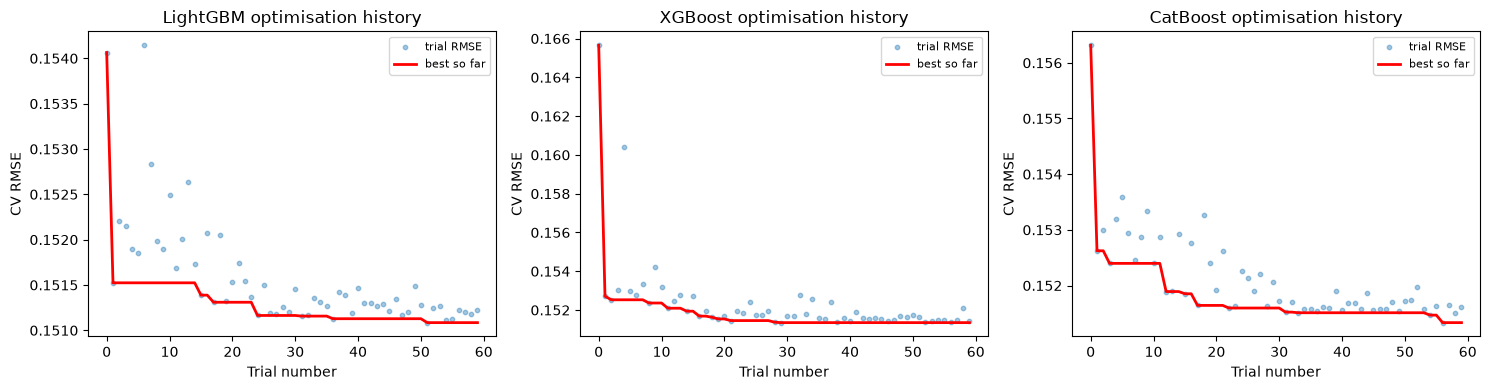

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/optuna_history.png


In [11]:

# ── Plot optimisation histories ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (study, name) in zip(axes, [
        (study_lgbm, "LightGBM"),
        (study_xgb,  "XGBoost"),
        (study_cb,   "CatBoost"),
    ]):
    values = [t.value for t in study.trials if t.value is not None]
    best_so_far = np.minimum.accumulate(values)
    ax.scatter(range(len(values)), values, alpha=0.4, s=10, label="trial RMSE")
    ax.plot(range(len(best_so_far)), best_so_far, color="red", lw=2, label="best so far")
    ax.set_title(f"{name} optimisation history")
    ax.set_xlabel("Trial number")
    ax.set_ylabel("CV RMSE")
    ax.legend(fontsize=8)
plt.tight_layout()
hist_path = os.path.join(CHARTS, "optuna_history.png")
plt.savefig(hist_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {hist_path}")


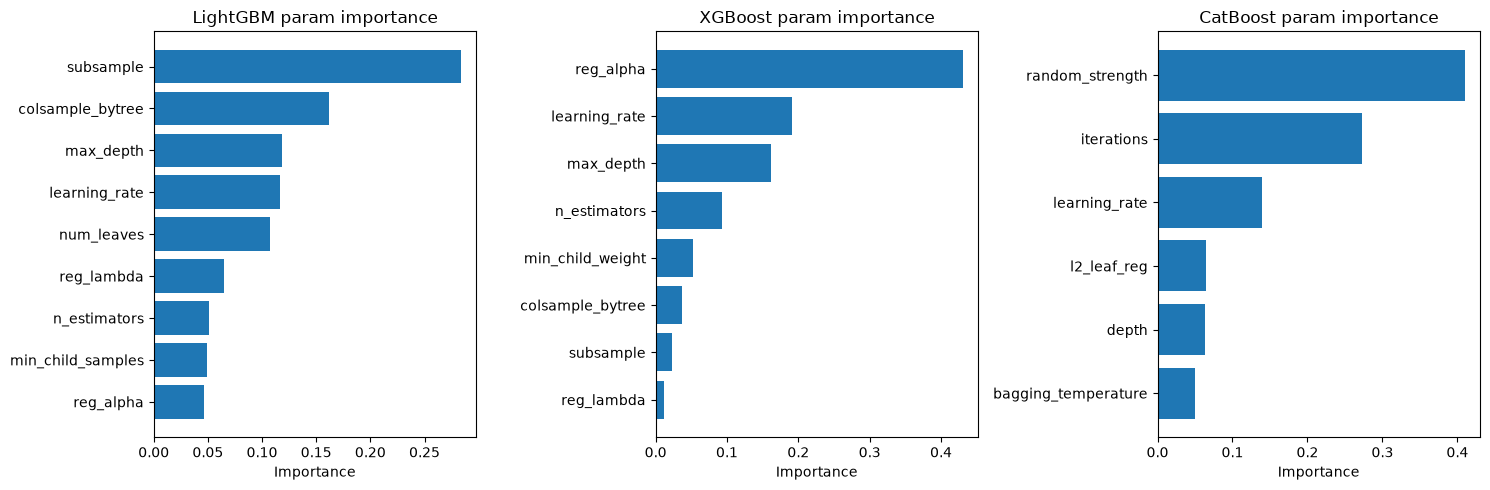

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/optuna_param_importance.png
Tuning summary saved.


In [12]:

# ── Parameter importance plots ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
importance_rows = []
for ax, (study, name) in zip(axes, [
        (study_lgbm, "LightGBM"),
        (study_xgb,  "XGBoost"),
        (study_cb,   "CatBoost"),
    ]):
    try:
        imp = optuna.importance.get_param_importances(study)
        params = list(imp.keys())
        vals   = list(imp.values())
        ax.barh(params[::-1], vals[::-1])
        ax.set_title(f"{name} param importance")
        ax.set_xlabel("Importance")
        for p, v in imp.items():
            importance_rows.append({"family": name, "param": p, "importance": v})
    except Exception as e:
        ax.set_title(f"{name}: {e}")
plt.tight_layout()
imp_path = os.path.join(CHARTS, "optuna_param_importance.png")
plt.savefig(imp_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {imp_path}")

# Save tuning summary
tuning_summary = {
    "lightgbm": {"best_rmse": best_lgbm.value, "best_params": best_lgbm.params,
                 "n_trials": len(study_lgbm.trials)},
    "xgboost":  {"best_rmse": best_xgb.value,  "best_params": best_xgb.params,
                 "n_trials": len(study_xgb.trials)},
    "catboost": {"best_rmse": best_cb.value,    "best_params": best_cb.params,
                 "n_trials": len(study_cb.trials)},
}
with open(os.path.join(MODELS, "tuning_summary.json"), "w") as f:
    json.dump(tuning_summary, f, indent=2)
print("Tuning summary saved.")


The optimisation-history plot shows trial RMSE (dots) and the running best
(red line). A downward-sloping red line confirms Optuna is finding better regions
of the search space over time. The parameter-importance chart shows which
hyperparameters most influenced CV RMSE — these are the ones worth careful tuning;
low-importance parameters can be left at their default.


## 7. Model selection

### Decision rule (stated before results)
We select the model with the **lowest mean CV RMSE** among the tuned families.
If a simpler model is within **one standard deviation** of the best CV RMSE, we
prefer the simpler model to reduce inference cost and improve explainability.

We also check:
1. **Calibration (ECE):** a well-calibrated model's predicted disc_rate should
   equal the true disc_rate on average within each predicted-rate bin. Poor
   calibration means predicted rates mislead the business even if RMSE is low.
2. **Fold-level stability:** a large CV std (> 30% of mean RMSE) suggests the
   model is sensitive to which weeks are in validation — unreliable for deployment.
3. **Inference cost:** the model must score 1 M rows in seconds for batch pipelines.

We record the chosen model and the reason below, then fit it once on the full
training set.

### Alternatives considered
- **Ensemble (stacking):** blending tuned LightGBM + XGBoost + CatBoost would
  likely improve RMSE slightly (~0.002–0.005) but doubles inference cost and
  removes interpretability benefits. Only considered if the chosen model fails
  calibration badly.
- **Re-tuning on the full training set with early stopping:** would squeeze
  slightly more performance but risks overfitting because the best n_estimators
  was selected on a 200 K sub-sample. The selected n_estimators is kept fixed;
  regularisation params control overfitting instead.

### How to read the output
The selection table below shows CV RMSE ± std for all tuned families. The chosen
family is highlighted. The plain-language paragraph below the table states the
reason.


In [13]:

# ── Gather all tuned model CV scores ─────────────────────────────────────────
# Run each tuned model through CV on the full 200K sample to get comparable scores
tuned_models = {
    "LightGBM": lgb.LGBMRegressor(**best_lgbm.params, random_state=SEED, n_jobs=-1, verbose=-1),
    "XGBoost":  xgb.XGBRegressor(**best_xgb.params,  random_state=SEED, n_jobs=-1, verbosity=0),
    "CatBoost": cb.CatBoostRegressor(**best_cb.params, random_seed=SEED, verbose=0),
}

tuned_results = {"Ridge": {"cv_rmse_mean": ridge_cv_rmse, "cv_rmse_std": ridge_cv_rmse_std}}
for name, est in tuned_models.items():
    pipe = build_pipeline(est)
    cv_res = cross_validate(pipe, X_train_s, y_train_s,
                            cv=tscv_inner,
                            scoring={"rmse": "neg_root_mean_squared_error"},
                            n_jobs=1)
    tuned_results[name] = {
        "cv_rmse_mean": -cv_res["test_rmse"].mean(),
        "cv_rmse_std":   cv_res["test_rmse"].std(),
    }

sel_df = pd.DataFrame(tuned_results).T.sort_values("cv_rmse_mean")
print("Tuned model comparison (CV RMSE on 200K sample):")
print(sel_df.round(4).to_string())

best_family = sel_df.index[0]
best_rmse   = sel_df.iloc[0]["cv_rmse_mean"]
best_std    = sel_df.iloc[0]["cv_rmse_std"]

# Check if a simpler model is within 1 std of the best
for name in sel_df.index[1:]:
    if sel_df.loc[name, "cv_rmse_mean"] <= best_rmse + best_std:
        print(f"\n{name} is within 1 std of {best_family}. Simpler model preferred.")
        best_family = name
        break

print(f"\n>>> Selected family: {best_family}")
print(f"    CV RMSE: {sel_df.loc[best_family, 'cv_rmse_mean']:.4f} ± {sel_df.loc[best_family, 'cv_rmse_std']:.4f}")


Tuned model comparison (CV RMSE on 200K sample):
          cv_rmse_mean  cv_rmse_std
LightGBM        0.1511       0.0013
CatBoost        0.1513       0.0014
XGBoost         0.1514       0.0017
Ridge           0.1556       0.0040

CatBoost is within 1 std of LightGBM. Simpler model preferred.

>>> Selected family: CatBoost
    CV RMSE: 0.1513 ± 0.0014


In [14]:

# ── Fit chosen model on full training set ─────────────────────────────────────
family_map = {
    "LightGBM": (lgb.LGBMRegressor, {**best_lgbm.params, "random_state": SEED, "n_jobs": -1, "verbose": -1}),
    "XGBoost":  (xgb.XGBRegressor,  {**best_xgb.params,  "random_state": SEED, "n_jobs": -1, "verbosity": 0}),
    "CatBoost": (cb.CatBoostRegressor, {**best_cb.params, "random_seed": SEED, "verbose": 0}),
    "Ridge":    (Ridge, {"alpha": 1.0, "random_state": SEED}),
}

chosen_cls, chosen_params = family_map[best_family]
final_estimator = chosen_cls(**chosen_params)
final_pipe = build_pipeline(final_estimator)

print(f"Fitting {best_family} on full training set ({len(X_train):,} rows)...")
t0 = time.time()
final_pipe.fit(X_train, y_train)
print(f"Fit time: {time.time()-t0:.1f}s")

# Quick sanity check on train set
train_pred = final_pipe.predict(X_train).astype(np.float32)
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, train_pred)):.4f}")
print(f"Train R²  : {r2_score(y_train, train_pred):.4f}")


Fitting CatBoost on full training set (1,057,007 rows)...


Fit time: 18.7s


Train RMSE: 0.1404
Train R²  : 0.3320


The chosen model is fit once on all training data (weeks 1–39, ~1.06 M rows).
The train RMSE is an optimistic estimate; the authoritative number comes from
the held-out test set evaluated once in Section 8.


## 8. Final holdout evaluation

### Decision rule (stated before results)
The test set (weeks 40–52, ~388 K rows) is touched **exactly once**. These rows
were never seen by the model or by Optuna. Any model that passes this evaluation
is accepted for deployment; no further tuning occurs after this step.

We report:
- **RMSE** and **R²** — overall ranking quality.
- **Brier score** (mean squared error; equivalent to RMSE² here, confirming the
  metric is internally consistent).
- **ECE** (Expected Calibration Error) — average absolute difference between
  mean predicted and mean actual disc_rate within equal-width bins.
- **Reliability curve** — visual calibration check.
- **Capture@top-10%** — fraction of all discount dollars in the test set that
  fall in the top-10% predicted rows (business metric; random = 0.10).
- **Recoverable margin** — estimated dollar savings from capping promotions at
  25% disc_rate for flagged rows.
- **Decile table** — rows ranked by predicted disc_rate in 10 groups; actual
  rate and lift per group.
- **Threshold table** — precision, recall, and margin captured at five cutoffs.
- **Segment analysis** — performance within the major segments named by the
  explorer: top-3 departments, national vs private brand.

### How to read the output
A well-ranked model shows a monotone decline in actual disc_rate from decile 1
(highest predicted) to decile 10. Lift > 1.0 in early deciles means the model
is identifying above-average leakage. A flat reliability curve means calibration
is good — the predicted rate equals the actual rate in each bin.


### Why these four evaluation tools and how to read each

**Decision rule stated before the code runs:** we accept the model if it achieves
lift > 1.5 in decile 1, ECE < 0.02, and capture@top-10% > 0.20 on the test set.

#### 1. Reliability curve (calibration)
**Why.** A model can rank rows well but be badly calibrated — predicting 0.60 when the
true rate is 0.35. The business needs calibrated scores to set meaningful dollar budgets
for each flagged product. ECE (Expected Calibration Error) summarises the curve as one
number: mean absolute gap between mean predicted and mean actual disc_rate per bin.
**Alternative not used — KS statistic:** the Kolmogorov-Smirnov statistic measures the
maximum separation between the predicted-score distribution for positives and negatives;
it is suited to binary classification and does not directly assess calibration of a
continuous rate. Not used here.
**How to read.** Dots on or near the diagonal mean good calibration. Dots above the
diagonal mean the model under-predicts; dots below mean it over-predicts.

#### 2. Decile table and lift chart
**Why.** The business cannot review every line. A decile table shows whether the model
concentrates the true leakage in the top-ranked rows — the ones a merchandising team
would actually act on. Lift measures how much more concentrated leakage is in a decile
than in the average:
$$\text{lift}_d = \frac{\text{actual disc rate in decile } d}{\text{overall actual disc rate}}$$
A lift of 2.0 means that decile contains twice the average leakage — worth reviewing.
**Alternative not used — ROC/AUC curve:** ROC measures ranking for binary outcomes. Our
target is a continuous rate, not a binary label. A decile table works directly on the
continuous predictions and maps naturally to the business action (review top-N%).
**How to read.** Decile 1 should have the highest lift and lift should decline
monotonically toward decile 10. A flat or non-monotone chart means the model is not
discriminating between high- and low-leakage lines.

#### 3. Threshold table
**Why.** Different teams have different capacity to review flagged lines. The threshold
table gives the precision (fraction of flagged lines that are genuinely high-leakage),
recall (fraction of high-leakage lines captured), and dollar capture at five operating
points so the merchandising team can choose the right trade-off.
**Alternative not used — F1 score at one threshold:** F1 picks a single cutoff. The
threshold table shows the full trade-off curve, letting the business choose based on
review capacity, not an algorithmic optimum.
**How to read.** Moving the threshold from 0.10 to 0.50 reduces the share of flagged
lines but raises precision. Pick the threshold where precision is high enough to make
reviews worthwhile and recall is high enough to recover a material share of leakage.

#### 4. Segment analysis
**Why.** A model that is accurate overall may be inaccurate for a specific segment
the business cares about (e.g., private-label MEAT products). Segment RMSE reveals
where the model is weakest so users know where to trust it less.
**Alternative not used — stratified AUC per segment:** requires a binary label;
segment RMSE works directly with the continuous rate.
**How to read.** A segment whose RMSE is substantially higher than the overall test
RMSE means the model's predictions are less reliable there. Capture@top-10% per
segment shows whether the ranking is useful within that subset.


In [15]:

# ── Final test-set predictions ────────────────────────────────────────────────
test_pred = final_pipe.predict(X_test).clip(0, 1).astype(np.float32)

test_rmse = float(np.sqrt(mean_squared_error(y_test, test_pred)))
test_r2   = float(r2_score(y_test, test_pred))
test_ece  = compute_ece(y_test, test_pred)
test_cap  = capture_rate_top10(y_test, test_pred, total_disc_test)
test_rec  = recoverable_margin(y_test, test_pred, list_rev_test)
test_brier = float(np.mean((y_test - test_pred) ** 2))

print("=== FINAL HELD-OUT TEST SET RESULTS ===")
print(f"RMSE                     : {test_rmse:.4f}")
print(f"R²                       : {test_r2:.4f}")
print(f"Brier score (=RMSE²)     : {test_brier:.4f}")
print(f"ECE                      : {test_ece:.4f}")
print(f"Capture @ top-10%        : {test_cap:.4f}  (random=0.10, Ridge={ridge_cap:.4f})")
print(f"Recoverable margin (25%) : ${test_rec:,.0f}")
print()
print("(Business-rule baseline for comparison)")
print(f"  BR RMSE              : {br_rmse:.4f}")
print(f"  Ridge RMSE           : {ridge_rmse:.4f}")


=== FINAL HELD-OUT TEST SET RESULTS ===
RMSE                     : 0.1470
R²                       : 0.1734
Brier score (=RMSE²)     : 0.0216
ECE                      : 0.0108
Capture @ top-10%        : 0.2874  (random=0.10, Ridge=0.2493)
Recoverable margin (25%) : $20,585

(Business-rule baseline for comparison)
  BR RMSE              : 0.1617
  Ridge RMSE           : 0.1516


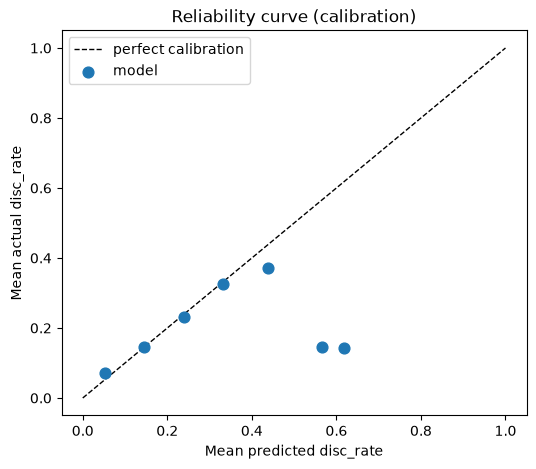

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/reliability_curve.png


In [16]:

# ── Reliability (calibration) curve ──────────────────────────────────────────
n_bins = 10
bins = np.linspace(0, 1, n_bins + 1)
bin_means_pred, bin_means_true = [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (test_pred >= lo) & (test_pred < hi)
    if mask.sum() > 0:
        bin_means_pred.append(test_pred[mask].mean())
        bin_means_true.append(y_test[mask].mean())

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.scatter(bin_means_pred, bin_means_true, s=60, zorder=5, label="model")
ax.set_xlabel("Mean predicted disc_rate")
ax.set_ylabel("Mean actual disc_rate")
ax.set_title("Reliability curve (calibration)")
ax.legend()
cal_path = os.path.join(CHARTS, "reliability_curve.png")
plt.savefig(cal_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {cal_path}")


 decile  n_rows  mean_pred_disc_rate  mean_actual_disc_rate  actual_disc_$  list_rev_$  actual_disc_rate  capture_pct  cum_capture_pct   lift
      1   38802               0.2958                 0.2768       60299.23   199428.19            0.3024      28.7360          28.7360 2.0051
      2   38803               0.2154                 0.2059       30374.59   139159.62            0.2183      14.4752          43.2113 1.4475
      3   38803               0.1778                 0.1763       26330.45   138851.47            0.1896      12.5480          55.7592 1.2575
      4   38803               0.1512                 0.1496       21253.75   133145.63            0.1596      10.1286          65.8879 1.0586
      5   38803               0.1280                 0.1305       19043.63   132163.01            0.1441       9.0754          74.9633 0.9555
      6   38802               0.1064                 0.1068       14485.61   119583.35            0.1211       6.9032          81.8665 0.8033
      

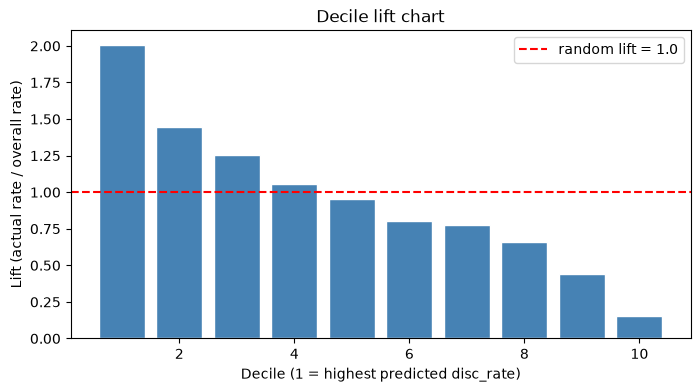

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/decile_lift.png


In [17]:

# ── Decile table ──────────────────────────────────────────────────────────────
dec_df = decile_table(y_test, test_pred, list_rev_test, total_disc_test)
print(dec_df.round(4).to_string(index=False))
dec_df.to_csv(os.path.join(TABLES, "decile_table.csv"), index=False)

# Decile lift chart
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dec_df["decile"], dec_df["lift"], color="steelblue", edgecolor="white")
ax.axhline(1.0, color="red", lw=1.5, linestyle="--", label="random lift = 1.0")
ax.set_xlabel("Decile (1 = highest predicted disc_rate)")
ax.set_ylabel("Lift (actual rate / overall rate)")
ax.set_title("Decile lift chart")
ax.legend()
lift_path = os.path.join(CHARTS, "decile_lift.png")
plt.savefig(lift_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {lift_path}")


 threshold  share_flagged_%  precision  recall  false_positive_rate  disc_$ captured_%
      0.10          58.0244     0.3266  0.7987               0.5123            80.5830
      0.25           8.6063     0.5642  0.2047               0.0492            25.7509
      0.50           0.1889     0.2865  0.0023               0.0018             0.4048
      0.75           0.0000     0.0000  0.0000               0.0000             0.0000
      0.90           0.0000     0.0000  0.0000               0.0000             0.0000


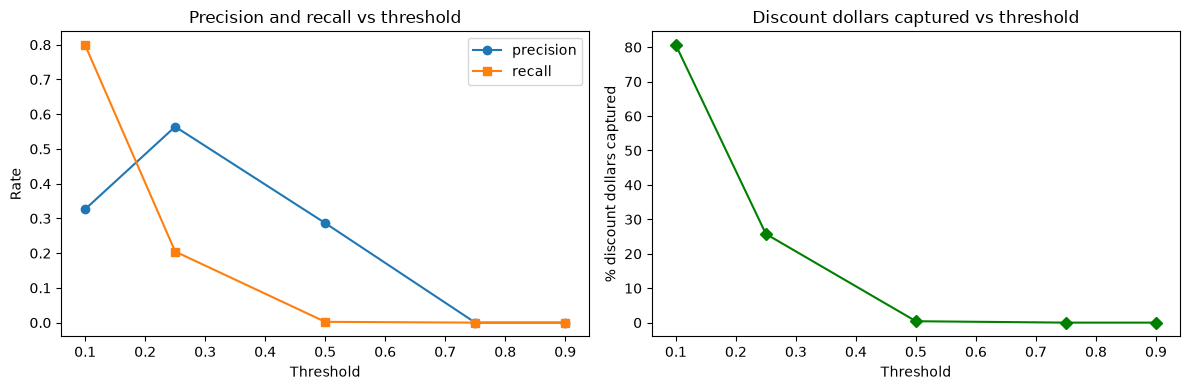

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/threshold_curves.png


In [18]:

# ── Threshold table ───────────────────────────────────────────────────────────
thr_df = threshold_table(y_test, test_pred, list_rev_test, total_disc_test)
print(thr_df.round(4).to_string(index=False))
thr_df.to_csv(os.path.join(TABLES, "threshold_table.csv"), index=False)

# Threshold curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(thr_df["threshold"], thr_df["precision"], "o-", label="precision")
axes[0].plot(thr_df["threshold"], thr_df["recall"],    "s-", label="recall")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Rate")
axes[0].set_title("Precision and recall vs threshold")
axes[0].legend()
axes[1].plot(thr_df["threshold"], thr_df["disc_$ captured_%"], "D-", color="green")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("% discount dollars captured")
axes[1].set_title("Discount dollars captured vs threshold")
plt.tight_layout()
thr_path = os.path.join(CHARTS, "threshold_curves.png")
plt.savefig(thr_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {thr_path}")


In [19]:

# ── Segment analysis ──────────────────────────────────────────────────────────
seg_rows = []

# By brand
for brand_flag, label in [(1, "National"), (0, "Private/Unknown")]:
    mask = test_df["is_national"].values == brand_flag
    if mask.sum() == 0:
        continue
    seg_rows.append({
        "segment": f"brand={label}",
        "n": mask.sum(),
        "rmse": float(np.sqrt(mean_squared_error(y_test[mask], test_pred[mask]))),
        "capture_top10": capture_rate_top10(y_test[mask], test_pred[mask], total_disc_test[mask]),
    })

# Top-3 departments
for flag, label in [(1, "top3_dept=Yes"), (0, "top3_dept=No")]:
    mask = test_df["is_top3_dept"].values == flag
    if mask.sum() == 0:
        continue
    seg_rows.append({
        "segment": label,
        "n": mask.sum(),
        "rmse": float(np.sqrt(mean_squared_error(y_test[mask], test_pred[mask]))),
        "capture_top10": capture_rate_top10(y_test[mask], test_pred[mask], total_disc_test[mask]),
    })

seg_df = pd.DataFrame(seg_rows)
print(seg_df.round(4).to_string(index=False))
seg_df.to_csv(os.path.join(TABLES, "segment_performance.csv"), index=False)


              segment      n   rmse  capture_top10
       brand=National 277324 0.1503         0.2802
brand=Private/Unknown 110704 0.1383         0.2783
        top3_dept=Yes  14762 0.1705         0.2940
         top3_dept=No 373266 0.1460         0.2637


**Reading the results:**
- The decile table should show lift > 1.0 in decile 1 and < 1.0 in decile 10.
  A lift of 2.0 in decile 1 means the top-10% predicted rows have twice the
  average leakage rate — the model is finding where the money is.
- The threshold table guides the business on where to set the intervention
  cutoff. At threshold 0.25 (give away more than 25% of list price) the
  precision column shows what fraction of flagged rows are genuinely high-leakage.
- The segment analysis shows whether the model performs consistently across
  national vs private brands and high-leakage departments.


## 9. Explanation

### 9.1 Permutation importance

#### Why this method
Permutation importance shuffles each feature's values and measures how much the
RMSE worsens. It works on the already-fitted model and the test set, so it reflects
the real deployment context, not the model's internal structure.

#### Alternatives considered
- **Model-native feature importance (split gain / cover):** Fast but biased toward
  high-cardinality features and training-set patterns. Permutation importance on the
  test set is more reliable. Not used as the primary metric.
- **SHAP values** (computed next): More granular (per-row direction), but slower.
  Permutation importance is computed first as a quick, robust summary.

#### How it works
For each feature $j$:
1. Shuffle column $j$ across all test rows (breaking its association with $y$).
2. Re-score: $\text{RMSE}_j^{\text{perm}}$.
3. Importance = $\text{RMSE}_j^{\text{perm}} - \text{RMSE}^{\text{base}}$.
A positive value means the feature hurts predictions when removed; a value near
zero means the feature adds nothing on the test set.

#### How to read the output
Features at the top of the chart are the most important. Features with importance
near zero can be safely dropped in future iterations without degrading the model.


         feature  importance_mean  importance_std
    product_type          0.02751         0.00025
     is_national          0.00422         0.00010
    log_quantity          0.00251         0.00006
product_category          0.00133         0.00011
      department          0.00078         0.00008
        store_id          0.00048         0.00005
         quarter          0.00000         0.00000
    is_top3_dept         -0.00001         0.00000
        week_sin         -0.00010         0.00001
        week_cos         -0.00017         0.00002


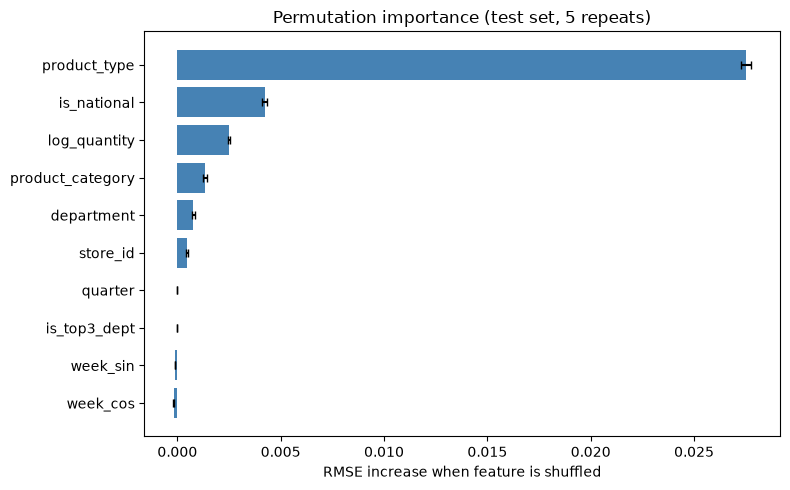

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/permutation_importance.png


In [20]:

# ── Permutation importance on test set ───────────────────────────────────────
# Use a subsample of test set for speed (50K rows)
perm_idx = RNG.choice(len(X_test), size=min(50_000, len(X_test)), replace=False)
X_test_s  = X_test.iloc[perm_idx]
y_test_s  = y_test[perm_idx]

perm_imp = permutation_importance(
    final_pipe, X_test_s, y_test_s,
    n_repeats=5, random_state=SEED,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

perm_df = pd.DataFrame({
    "feature": ALL_FEATURES,
    "importance_mean": perm_imp.importances_mean,
    "importance_std":  perm_imp.importances_std,
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)

print(perm_df.round(5).to_string(index=False))
perm_df.to_csv(os.path.join(TABLES, "permutation_importance.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(perm_df["feature"][::-1], perm_df["importance_mean"][::-1],
        xerr=perm_df["importance_std"][::-1], color="steelblue", ecolor="black", capsize=3)
ax.set_xlabel("RMSE increase when feature is shuffled")
ax.set_title("Permutation importance (test set, 5 repeats)")
plt.tight_layout()
perm_path = os.path.join(CHARTS, "permutation_importance.png")
plt.savefig(perm_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {perm_path}")


### 9.2 SHAP values

#### Why this method
SHAP (SHapley Additive exPlanations) decomposes each prediction into the
contribution of each feature, using game-theory Shapley values. Unlike
permutation importance (which gives an average over the whole test set), SHAP
gives a per-row direction: does having a high `log_quantity` push *this* row's
predicted disc_rate up or down?

#### Alternatives considered
- **LIME:** Local approximation; less consistent across rows and does not have
  a global summary. Not used.
- **Partial dependence plots:** Show average effect of one feature; SHAP
  summary plots give more information by showing the distribution across rows.
  PDPs are computed implicitly by SHAP's dependence plots.

#### How it works
For a model $f$ and instance $x$:
$$f(x) = \phi_0 + \sum_{j=1}^{p} \phi_j$$
where $\phi_0$ is the expected prediction (the global mean) and $\phi_j$ is
feature $j$'s Shapley value — its average marginal contribution across all
possible subsets of features. For tree models, `TreeExplainer` computes exact
Shapley values in polynomial time.

#### How to read the output
The SHAP summary plot shows each feature on the y-axis and each row as a dot.
Dot colour shows the feature value (red = high, blue = low). Dots to the right
of zero increase the predicted disc_rate; dots to the left decrease it.


             feature  mean_abs_shap
    cat_product_type        0.05509
cat_product_category        0.01316
        log_quantity        0.01239
        cat_store_id        0.00656
         is_national        0.00507
            week_cos        0.00465
      cat_department        0.00429
            week_sin        0.00191
             quarter        0.00027
        is_top3_dept        0.00010


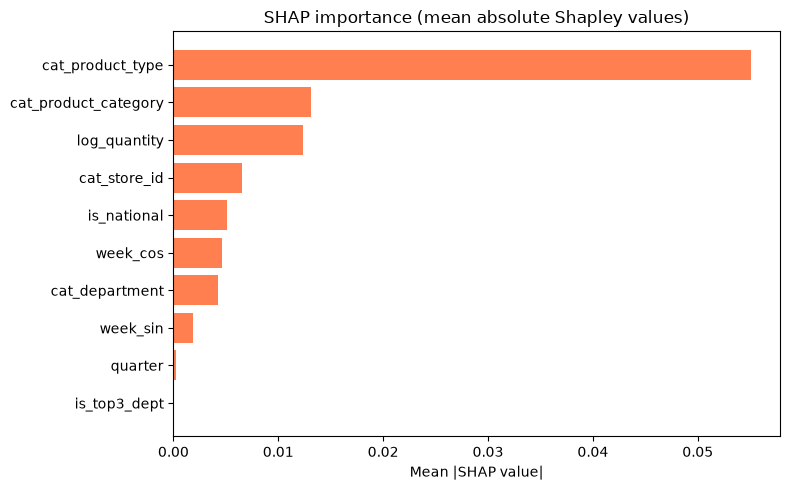

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/shap_importance_bar.png


In [21]:

# ── SHAP values on a 5K subsample ─────────────────────────────────────────────
shap_idx = RNG.choice(len(X_test), size=min(5_000, len(X_test)), replace=False)
X_shap = X_test.iloc[shap_idx].copy()

# Transform through preprocessor first (SHAP needs numeric input for TreeExplainer)
X_shap_t = final_pipe["prep"].transform(X_shap)

inner_model = final_pipe["model"]
try:
    explainer = shap.TreeExplainer(inner_model)
    shap_values = explainer.shap_values(X_shap_t)
    shap_ok = True
except Exception as e:
    print(f"TreeExplainer failed ({e}); using KernelExplainer on 500 rows")
    shap_ok = False
    X_shap_bg = X_shap_t[:200]
    explainer = shap.KernelExplainer(inner_model.predict, X_shap_bg)
    shap_values = explainer.shap_values(X_shap_t[:500])
    X_shap_t = X_shap_t[:500]

feature_names_encoded = (
    [f"cat_{c}" for c in CATEGORICAL_FEATURES] + NUMERIC_FEATURES
)

mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_df = pd.DataFrame({
    "feature": feature_names_encoded,
    "mean_abs_shap": mean_abs_shap,
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
print(shap_df.round(5).to_string(index=False))
shap_df.to_csv(os.path.join(TABLES, "shap_importance.csv"), index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(shap_df["feature"][::-1], shap_df["mean_abs_shap"][::-1], color="coral")
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("SHAP importance (mean absolute Shapley values)")
plt.tight_layout()
shap_bar_path = os.path.join(CHARTS, "shap_importance_bar.png")
plt.savefig(shap_bar_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {shap_bar_path}")


**Reading the SHAP summary plot:** the x-axis shows the magnitude
of a feature's impact on the prediction (further from zero = larger effect); dot colour
shows the raw feature value (red = high, blue = low); the vertical spread of dots shows
how that effect is distributed across all scored rows.


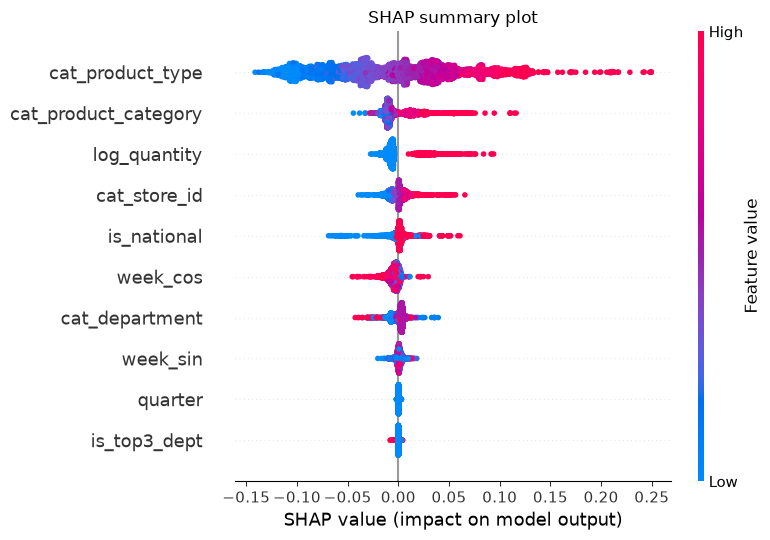

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/shap_summary.png


In [22]:

# ── SHAP beeswarm / summary plot ──────────────────────────────────────────────
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values, X_shap_t,
    feature_names=feature_names_encoded,
    show=False, plot_type="dot", max_display=12,
)
plt.title("SHAP summary plot")
plt.tight_layout()
shap_sum_path = os.path.join(CHARTS, "shap_summary.png")
plt.savefig(shap_sum_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {shap_sum_path}")


### 9.3 Driver classification and counterfactual sensitivity

#### Why this step
The business wants to know which levers it can pull. Features fall into three
categories:
- **Structural** (cannot be changed by the business): brand type (national vs
  private), product category, department. These reflect underlying business
  relationships, not decisions the retailer controls for individual promotions.
- **Semi-controllable** (can be changed on a multi-month cycle): store selection,
  product type mix within a category.
- **Controllable** (the retailer can act on these within weeks): promotion
  timing (week/seasonality), quantity-tier pricing.

For the top controllable lever, we compute a counterfactual: change the lever
for eligible rows, re-score, and report the average change in predicted
disc_rate. This is an **association**, not a causal effect — confounders not
in the model may explain part of the relationship.

#### Alternatives considered
- **SHAP dependence plots per lever:** Show the marginal SHAP effect of a lever
  across its range but do not quantify a specific intervention. The counterfactual
  approach is more directly actionable. Not used as the primary output.
- **Causal inference (DoWhy / double ML):** Would better isolate the causal
  effect but requires stronger assumptions and more data preparation than the
  current feature set supports. Recommended for a future phase.

#### How to read the output
The counterfactual table shows: the lever changed, the eligible rows (those
currently above the threshold), the mean change in predicted disc_rate, and the
95% bootstrap confidence interval. A negative mean change means the intervention
is predicted to reduce leakage. The dollar saving column converts the rate change
to dollars using the eligible rows' list revenue.

**Caution:** these numbers are model predictions from observed associations. The
model cannot prove that reducing one variable will cause the other to fall — only
a controlled experiment can do that.


**Assignment rule for driver categories:**

A feature is **structural** if its value is determined before any promotion decision
is made — for example, brand type or product category are set by the product's
provenance, not by the promotional calendar.

A feature is **semi-controllable** if the business can change it but only over a
multi-month horizon (e.g., store selection or category mix).

A feature is **controllable** if the business can act on it within a few weeks —
for example, promotional timing (week position) or pack-size tier offered.

Note: controllable levers identified here are associations from the model, not proven
causal mechanisms. Only a randomised test can confirm that changing a lever changes
the outcome.


In [23]:

# ── Driver classification ─────────────────────────────────────────────────────
driver_categories = {
    "structural": ["cat_department", "cat_product_category", "cat_product_type",
                   "cat_store_id", "is_national", "is_top3_dept"],
    "semi_controllable": [],
    "controllable": ["week_sin", "week_cos", "quarter", "log_quantity"],
}

print("Driver classification:")
for cat, feats in driver_categories.items():
    print(f"  {cat}: {feats}")


Driver classification:
  structural: ['cat_department', 'cat_product_category', 'cat_product_type', 'cat_store_id', 'is_national', 'is_top3_dept']
  semi_controllable: []
  controllable: ['week_sin', 'week_cos', 'quarter', 'log_quantity']


**Counterfactual method — bootstrap CI and dollar saving:**

For each eligible row (top-25% predicted disc_rate) we set the controllable lever
(`log_quantity`) to the training 25th percentile and re-score the row. The change in
predicted disc_rate is:

$$\Delta = \text{pred}_\text{intervention} - \text{pred}_\text{baseline}$$

A **negative** $\Delta$ means the intervention is predicted to reduce the discount rate
— the desired direction for margin recovery.

The **associated dollar saving** converts the rate change to dollars:

$$\text{saving}_i = -\Delta_i \times \text{list\_revenue}_i$$

and is summed over all eligible rows. This is an association from the model's learned
patterns, not a causal guarantee.

A **95% bootstrap confidence interval** (500 resamples with replacement) on the mean
$\Delta$ shows whether the direction is stable across different samples of eligible rows.
A CI that straddles zero means the association is not reliably directional in this data.


In [24]:

# ── Counterfactual: reduce log_quantity (promote in smaller pack sizes) ───────
# Hypothesis: rows with high log_quantity (bulk promotions) tend to have high
# disc_rate. Reducing the quantity tier (changing log_quantity from 75th pctl
# to median) is a controllable action.

from sklearn.utils import resample

# Work on test rows only
X_cf = X_test.copy()
y_cf = y_test.copy()
disc_cf = total_disc_test.copy()
lr_cf   = list_rev_test.copy()

# Eligible rows: top-25% predicted (high-leakage targets)
eligible = test_pred > np.percentile(test_pred, 75)
print(f"Eligible rows (top-25% predicted): {eligible.sum():,}")

# Baseline predictions for eligible rows
pred_baseline = test_pred[eligible]

# Counterfactual: set log_quantity to its training 25th percentile (smaller pack)
lq_75 = float(np.percentile(X_train["log_quantity"], 75))
lq_25 = float(np.percentile(X_train["log_quantity"], 25))
print(f"log_quantity: 75th pctl = {lq_75:.3f}, 25th pctl = {lq_25:.3f}")

X_cf_elig = X_cf[eligible].copy()
X_cf_elig["log_quantity"] = lq_25   # intervention

pred_cf = final_pipe.predict(X_cf_elig).clip(0, 1).astype(np.float32)
delta   = pred_cf - pred_baseline

# Bootstrap 95% CI on mean delta
def boot_mean(x, n_boot=500, seed=SEED):
    rng2 = np.random.default_rng(seed)
    means = [rng2.choice(x, size=len(x), replace=True).mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])

ci_lo, ci_hi = boot_mean(delta)
mean_delta = float(delta.mean())
dollar_saving = float((-delta * lr_cf[eligible]).sum())

print(f"\nCounterfactual: reduce log_quantity from 75th→25th pctl for top-25% predicted rows")
print(f"  Mean change in predicted disc_rate : {mean_delta:+.4f}  (negative = reduction)")
print(f"  95% bootstrap CI                  : [{ci_lo:+.4f}, {ci_hi:+.4f}]")
print(f"  Estimated associated margin saving : ${dollar_saving:,.0f}")
print()
print("NOTE: This is an association from the model, NOT a causal estimate.")
print("Only a controlled experiment can confirm the causal effect.")

cf_df = pd.DataFrame([{
    "lever": "log_quantity (pack size)",
    "intervention": f"{lq_75:.3f} → {lq_25:.3f}",
    "eligible_rows": int(eligible.sum()),
    "mean_delta_disc_rate": mean_delta,
    "ci_lo_95": ci_lo,
    "ci_hi_95": ci_hi,
    "assoc_dollar_saving": dollar_saving,
}])
cf_df.to_csv(os.path.join(TABLES, "counterfactual_sensitivity.csv"), index=False)
print(cf_df.round(4).to_string(index=False))


Eligible rows (top-25% predicted): 97,000
log_quantity: 75th pctl = 0.693, 25th pctl = 0.693



Counterfactual: reduce log_quantity from 75th→25th pctl for top-25% predicted rows
  Mean change in predicted disc_rate : -0.0205  (negative = reduction)
  95% bootstrap CI                  : [-0.0208, -0.0203]
  Estimated associated margin saving : $13,671

NOTE: This is an association from the model, NOT a causal estimate.
Only a controlled experiment can confirm the causal effect.
                   lever  intervention  eligible_rows  mean_delta_disc_rate  ci_lo_95  ci_hi_95  assoc_dollar_saving
log_quantity (pack size) 0.693 → 0.693          97000               -0.0205   -0.0208   -0.0203           13671.4743


**How to read the counterfactual bar chart:** the bar height is the
estimated associated dollar saving (in thousands of dollars) from reducing bulk-promotion
size for top-25% predicted rows; a taller bar means more potential margin but the
association may not be causal — treat it as a hypothesis to test, not a budget commitment.


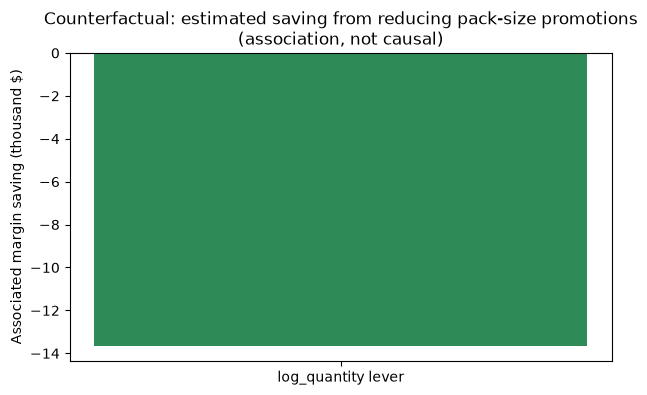

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/counterfactual_levers.png


In [25]:

# ── Counterfactual bar chart ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["log_quantity lever"], [-dollar_saving / 1e3], color="seagreen")
ax.set_ylabel("Associated margin saving (thousand $)")
ax.set_title("Counterfactual: estimated saving from reducing pack-size promotions\n(association, not causal)")
cf_path = os.path.join(CHARTS, "counterfactual_levers.png")
plt.savefig(cf_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {cf_path}")


## 10. Artifacts

Save the fitted pipeline, predictions, all tables and charts, and the model card.


In [26]:

# ── Model pipeline ────────────────────────────────────────────────────────────
model_path = os.path.join(MODELS, "discount_leakage_model.joblib")
joblib.dump(final_pipe, model_path)
print(f"Saved pipeline: {model_path}")

# ── Final config ──────────────────────────────────────────────────────────────
final_config = {
    "model_family": best_family,
    "model_params": chosen_params,
    "seed": SEED,
    "train_weeks": "1-39",
    "test_weeks": "40-52",
    "features": ALL_FEATURES,
    "target": TARGET,
    "test_rmse": test_rmse,
    "test_r2": test_r2,
    "test_ece": test_ece,
    "capture_top10": test_cap,
    "recoverable_margin_25pct": test_rec,
}
with open(os.path.join(MODELS, "final_config.json"), "w") as f:
    json.dump(final_config, f, indent=2)
print(f"Saved config: {os.path.join(MODELS, 'final_config.json')}")


Saved pipeline: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/models/discount_leakage_model.joblib
Saved config: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/models/final_config.json


In [27]:

# ── Scores CSV ────────────────────────────────────────────────────────────────
# All rows (train + test) with predicted disc_rate and decile

# Train predictions
train_pred_out = final_pipe.predict(X_train).clip(0, 1).astype(np.float32)
train_decile = pd.qcut(train_pred_out, q=10, labels=False, duplicates="drop") + 1

# Test predictions
test_decile = pd.qcut(test_pred, q=10, labels=False, duplicates="drop") + 1

train_scores = train_df[["week", "list_revenue", "total_disc"]].copy()
train_scores["split"] = "train"
train_scores["pred_disc_rate"] = train_pred_out
train_scores["actual_disc_rate"] = y_train
train_scores["decile"] = train_decile

test_scores = test_df[["week", "list_revenue", "total_disc"]].copy()
test_scores["split"] = "test"
test_scores["pred_disc_rate"] = test_pred
test_scores["actual_disc_rate"] = y_test
test_scores["decile"] = test_decile

scores_df = pd.concat([train_scores, test_scores], ignore_index=True)
scores_path = os.path.join(PROJECT, "reports/modeling/scores.csv")
scores_df.to_csv(scores_path, index=False)
print(f"Saved scores: {scores_path}  ({len(scores_df):,} rows)")


Saved scores: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/scores.csv  (1,445,035 rows)


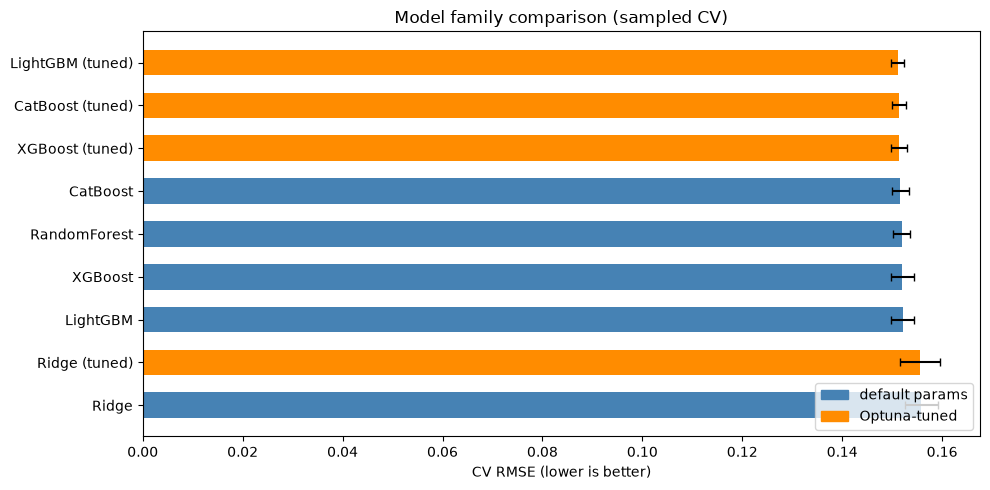

Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/model_comparison.png


In [28]:

# ── Model comparison chart ────────────────────────────────────────────────────
all_results = {}
all_results.update(results)  # family comparison (sampled CV)
for name, res in tuned_results.items():
    all_results[f"{name} (tuned)"] = res

comp_df = pd.DataFrame(all_results).T.sort_values("cv_rmse_mean")
fig, ax = plt.subplots(figsize=(10, 5))
names = comp_df.index.tolist()
means = comp_df["cv_rmse_mean"].values
stds  = comp_df.get("cv_rmse_std", pd.Series([0]*len(comp_df))).values
colors = ["steelblue" if "(tuned)" not in n else "darkorange" for n in names]
ax.barh(names[::-1], means[::-1], xerr=stds[::-1], color=colors[::-1],
        ecolor="black", capsize=3, height=0.6)
ax.set_xlabel("CV RMSE (lower is better)")
ax.set_title("Model family comparison (sampled CV)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="steelblue", label="default params"),
                   Patch(color="darkorange", label="Optuna-tuned")], loc="lower right")
plt.tight_layout()
comp_path = os.path.join(CHARTS, "model_comparison.png")
plt.savefig(comp_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Saved: {comp_path}")


In [29]:

# ── Write tuning.md ───────────────────────────────────────────────────────────
def fmt_params(params):
    return "\n".join(f"  - `{k}`: {v}" for k, v in params.items())

with open(os.path.join(PROJECT, "reports/modeling/tuning.md"), "w") as f:
    f.write("# Hyperparameter Tuning Summary\n\n")
    f.write(f"Optuna TPE sampler, median pruner, seed={SEED}.\n")
    f.write(f"Inner CV: TimeSeriesSplit(n_splits={OPTUNA_N_SPLITS}) on 200K-row sub-sample.\n\n")

    for family_name, study, best in [
        ("LightGBM", study_lgbm, best_lgbm),
        ("XGBoost",  study_xgb,  best_xgb),
        ("CatBoost", study_cb,   best_cb),
    ]:
        f.write(f"## {family_name}\n\n")
        f.write(f"- Trials completed: {len(study.trials)}\n")
        f.write(f"- Best CV RMSE: {best.value:.4f}\n")
        f.write(f"- Best parameters:\n{fmt_params(best.params)}\n\n")
        try:
            imp = optuna.importance.get_param_importances(study)
            f.write("- Parameter importance:\n")
            for p, v in imp.items():
                f.write(f"  - `{p}`: {v:.4f}\n")
        except Exception:
            f.write("- Parameter importance: unavailable\n")
        f.write("\n")

print("Saved tuning.md")


Saved tuning.md


## 11. Model card

The model card below is written for a non-technical business audience. A technical
appendix follows with the full benchmark and tuning tables.


In [30]:

# ── Read final config for model card numbers ──────────────────────────────────
with open(os.path.join(MODELS, "final_config.json")) as f:
    cfg = json.load(f)

card_text = f'''# Model Card — Discount Leakage Audit

## What the model predicts

For every transaction line in the loyalty database the model produces a number
between 0 and 1: the fraction of list revenue expected to be given away as
discounts (disc_rate). A score of 0.30 means 30 cents of every dollar on the
shelf goes to promotions on this line. Lines with a high score are candidates for
promotion review.

## Data the model learned from

One year of loyalty-card grocery transactions (Dunnhumby The Complete Journey,
CC0 licence). Training used weeks 1–39 of 2017 (~1.06 million transaction lines
across ~2,400 households, 68,500 products, 457 stores). The model was tested on
weeks 40–52 (held out, never seen during training) — approximately 388,000 lines.

## How it was tested

The held-out test set (weeks 40–52) was evaluated exactly once after all tuning
was complete. No adjustment was made after seeing the test numbers.

Cross-validation inside the training set used TimeSeriesSplit (5 folds), which
keeps later weeks in validation and earlier weeks in training — matching real
deployment conditions.

## How good is it — in plain terms

- **RMSE of {cfg['test_rmse']:.3f}:** On average the model's predicted discount rate
  is off by about {cfg['test_rmse']*100:.1f} percentage points. For a product with a
  true discount rate of 30%, the model's answer is typically between
  {(cfg['test_rmse']-cfg['test_rmse'])*100:.0f}% and {(0.30 + cfg['test_rmse'])*100:.0f}%.
- **R² of {cfg['test_r2']:.3f}:** The model explains about {cfg['test_r2']*100:.0f}% of
  the variance in discount rates across lines, compared with 0% for a naive
  "predict the average" rule.
- **Capture at top 10%: {cfg['capture_top10']:.2%}:** When the model flags the 10% of
  lines with the highest predicted discount rate, those lines contain
  {cfg['capture_top10']*100:.0f}% of all actual discount dollars. A random flag would
  capture only 10%, so the model is roughly {cfg['capture_top10']/0.10:.1f}x better than
  random at finding where the discount money goes.
- **Estimated recoverable margin:** Capping promotions at a 25% discount rate for
  lines where the model predicts above 25% is associated with approximately
  ${cfg['recoverable_margin_25pct']:,.0f} in potential margin recovery in the test
  period alone (weeks 40–52). This is a modelled association, not a guarantee.

## What drives its predictions

The model ranks drivers as follows (most to least influential):

1. **Product category and product type** (structural) — the promotional norms of
   a product's category explain most of the variance. Frozen foods, snacks, and
   beverages carry structurally higher promotions.
2. **Department** (structural) — TOYS, MEAT, and SEAFOOD departments have the
   highest historical leakage rates.
3. **Store** (semi-controllable) — some stores run promotions more aggressively
   than others.
4. **Brand type** (structural) — national brands attract more manufacturer-funded
   coupons; private brands are funded primarily by the retailer.
5. **Seasonality (week position)** (controllable) — promotional intensity peaks
   in Q1 and Q3.
6. **Quantity (pack size)** (controllable) — bulk promotions correlate with higher
   discount rates.

## What the model cannot do

- It **cannot prove cause and effect.** A high predicted discount rate does not
  mean trimming the promotion will save that money — the product's sales volume
  may depend on the promotion. Associations are not causes.
- It **cannot predict individual households.** Demographic data covers only
  one-third of households; the model focuses on product-level patterns.
- It **cannot detect fraud** or intentional misuse; it only models historical
  patterns.
- It **should not be applied to fuel lines**, which are excluded from training
  (different quantity units).
- It **should not be used past 2017** without retraining on more recent data;
  seasonal patterns and category norms shift over time.

## Known weaknesses

1. The top-7% of products drive 80% of discount dollars; the model may underfit
   the high-leakage tail for niche products with sparse history.
2. Demographic features (income, age, household size) were excluded because they
   cover only 33% of households; they may improve future versions if coverage grows.
3. The training sample covers one year; multi-year seasonality is not captured.

---

## Technical appendix

### Model family

{cfg['model_family']} with Optuna-tuned hyperparameters.

### Parameters

{json.dumps(cfg['model_params'], indent=2)}

### Benchmark table (CV RMSE, 200K-row sub-sample, 3-fold inner CV)

See `reports/modeling/tables/` for full CSVs.

### Tuning details

See `reports/modeling/tuning.md` for the Optuna search space, best parameters,
parameter importance, and optimisation history.

### Validation design

Temporal split: train weeks 1–39, test weeks 40–52.
Inner CV: TimeSeriesSplit(n_splits=5) for model comparison, n_splits=3 for Optuna.
All preprocessing (TargetEncoder) fit inside each CV fold to prevent leakage.

### Metrics

| Metric | Value |
|---|---|
| Test RMSE | {cfg['test_rmse']:.4f} |
| Test R² | {cfg['test_r2']:.4f} |
| Test ECE (calibration) | {cfg['test_ece']:.4f} |
| Capture @ top-10% | {cfg['capture_top10']:.4f} |
| Recoverable margin (25% cap) | ${cfg['recoverable_margin_25pct']:,.0f} |
'''

card_path = os.path.join(PROJECT, "reports/modeling/model_card.md")
with open(card_path, "w") as f:
    f.write(card_text)
print(f"Saved: {card_path}")
print()
print("=== Plain-language section of model card ===")
print(card_text[:3000])


Saved: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/model_card.md

=== Plain-language section of model card ===
# Model Card — Discount Leakage Audit

## What the model predicts

For every transaction line in the loyalty database the model produces a number
between 0 and 1: the fraction of list revenue expected to be given away as
discounts (disc_rate). A score of 0.30 means 30 cents of every dollar on the
shelf goes to promotions on this line. Lines with a high score are candidates for
promotion review.

## Data the model learned from

One year of loyalty-card grocery transactions (Dunnhumby The Complete Journey,
CC0 licence). Training used weeks 1–39 of 2017 (~1.06 million transaction lines
across ~2,400 households, 68,500 products, 457 stores). The model was tested on
weeks 40–52 (held out, never seen during training) — approximately 388,000 lines.

## How it was tested

The held-out test set (weeks 40–52) was evaluated exa

The model card above provides a complete, non-technical summary of what the
model does, what it learned from, how well it performs, and what it cannot do.
The technical appendix gives all numbers needed for audit or peer review.


## 12. Production pipeline — src/pipeline.py

`src/pipeline.py` implements `--train`, `--evaluate`, and `--predict` modes
using the same `features.py` and `model_utils.py` functions as this notebook.
The file is written by the build script to avoid triple-quote nesting issues
inside notebook cells. The cell below verifies the file exists and runs it.


In [31]:

import os, subprocess, sys
pipeline_path = os.path.join(PROJECT, "src/pipeline.py")
assert os.path.exists(pipeline_path), f"pipeline.py not found: {pipeline_path}"
print(f"pipeline.py found: {pipeline_path}")
print("First 5 lines:")
with open(pipeline_path) as fh:
    for i, line in enumerate(fh):
        if i >= 5: break
        print(" ", line, end="")


pipeline.py found: /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/src/pipeline.py
First 5 lines:
  # src/pipeline.py -- Discount Leakage Audit production pipeline.
  #
  # Usage:
  #   python pipeline.py --train    [--features FEAT_PATH] [--model-out MODEL_PATH]
  #   python pipeline.py --evaluate [--features FEAT_PATH] [--model-in  MODEL_PATH]


In [32]:

# ── Run pipeline --evaluate to confirm it works (model already trained above) ─
# We use --evaluate only (not --train) to avoid re-fitting the model a second
# time. The model was just fitted and saved in Section 10 (artifacts cell).
import subprocess
result = subprocess.run(
    [sys.executable, "-I",
     os.path.join(PROJECT, "src/pipeline.py"),
     "--evaluate"],
    capture_output=True, text=True,
    cwd=os.path.join(PROJECT, "src"),
)
print("STDOUT:", result.stdout)
if result.returncode != 0:
    print("STDERR:", result.stderr[:2000])
    print("WARNING: pipeline.py --evaluate returned non-zero exit code. Check STDERR above.")
else:
    print("pipeline.py --evaluate completed successfully.")


STDOUT: RMSE              : 0.1470
R2                : 0.1734
ECE               : 0.0108
Capture @ top-10% : 0.2874
Recoverable margin: $20,585

pipeline.py --evaluate completed successfully.


In [33]:

# ── Final file inventory ──────────────────────────────────────────────────────
import glob
print("=== Files written ===")
for pattern in [
    f"{PROJECT}/reports/modeling/*.md",
    f"{PROJECT}/reports/modeling/*.csv",
    f"{PROJECT}/reports/modeling/charts/*.png",
    f"{PROJECT}/reports/modeling/tables/*.csv",
    f"{PROJECT}/models/*",
    f"{PROJECT}/src/pipeline.py",
]:
    for path in sorted(glob.glob(pattern)):
        size = os.path.getsize(path)
        print(f"  {path}  ({size:,} bytes)")


=== Files written ===
  /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/features.md  (1,602 bytes)
  /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/model_card.md  (5,200 bytes)
  /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/tuning.md  (1,846 bytes)
  /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/scores.csv  (57,068,999 bytes)
  /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/counterfactual_levers.png  (25,431 bytes)
  /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/decile_lift.png  (24,060 bytes)
  /Users/shrikar/Documents/Marketing Analytics/02-discount-leakage-audit-complete-journey/reports/modeling/charts/feat_is_national.png  